# Scatter with Regression Line

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

A scatter plot with a fitted trend line and its confidence band. The fit summarises the relationship, the band shows how certain the estimate is, and the raw points stay visible as evidence.

## When to use

- Show the direction and strength of a roughly linear relationship
- Report a correlation coefficient or slope alongside the data
- Show model fit and the uncertainty around it

## Avoid when

- The relationship is clearly non-linear (use LOWESS or a polynomial fit)
- Readers might read the trend line as proof of causation
- Outliers dominate the fit (check robust alternatives first)

## Alternatives

- LOWESS-smoothed scatter
- Joint plot
- Residual plot

## Design tips

- Annotate r (or R²) and n in a corner
- Make the band lighter than the line and the points lighter than both

## Example

Weekly advertising spend vs. sales for 80 weeks, with an OLS fit and 95% confidence band.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
from scipy import stats
rng = np.random.default_rng(1)
spend = rng.uniform(5, 50, 80)
sales = 120 + 6.2 * spend + rng.normal(0, 40, 80)
df = pd.DataFrame({"ad_spend_k": spend, "sales_k": sales})
x, y = "ad_spend_k", "sales_k"
labels = dict(x="Advertising spend ($k / week)", y="Sales ($k / week)", title="Sales rise with advertising spend")
fit = stats.linregress(df[x], df[y])
print(f"slope={fit.slope:.2f}  r={fit.rvalue:.2f}  p={fit.pvalue:.1e}")

slope=6.77  r=0.92  p=5.3e-34


### Plot

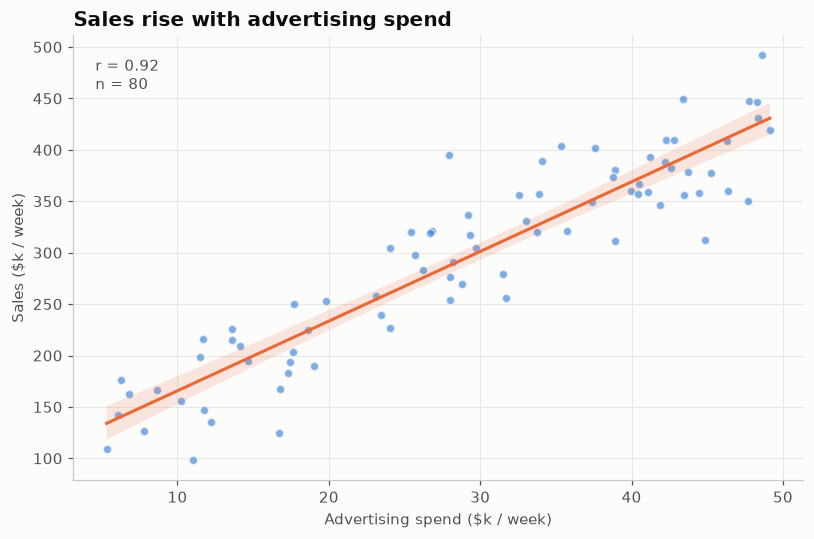

In [3]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.regplot(data=df, x=x, y=y, ax=ax, ci=95, seed=0,
            scatter_kws=dict(s=30, alpha=0.6, color=PALETTE[0], edgecolor="#fcfcfb"),
            line_kws=dict(color=PALETTE[1], linewidth=2))
ax.text(0.03, 0.95, f"r = {fit.rvalue:.2f}\nn = {len(df)}", transform=ax.transAxes,
        va="top", fontsize=10, color="#52514e")
ax.set_xlabel(labels["x"])
ax.set_ylabel(labels["y"])
ax.set_title(labels["title"])
fig.tight_layout()
plt.show()

## How to read it

The orange line is the best linear fit and the shaded band is its 95% confidence interval. The band is narrowest near the mean spend, where the data is densest.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.scatter(df, x=x, y=y, trendline="ols", opacity=0.65,
                 color_discrete_sequence=PALETTE, trendline_color_override=PALETTE[1],
                 labels={x: labels["x"], y: labels["y"]}, title=labels["title"])
fig.show()   # hover the line for the fitted equation and R²

## Try it with real data

**Source:** plotly.express.data.tips() — 244 restaurant bills and tips (Bryant & Smith 1995), bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [5]:
from scipy import stats
import plotly.express as px
df = px.data.tips()
x, y = "total_bill", "tip"
labels = dict(x="Total bill ($)", y="Tip ($)",
              title="Tips rise with the size of the bill (244 restaurant bills)")
fit = stats.linregress(df[x], df[y])
print(f"slope={fit.slope:.2f}  r={fit.rvalue:.2f}  p={fit.pvalue:.1e}")

slope=0.11  r=0.68  p=6.7e-34


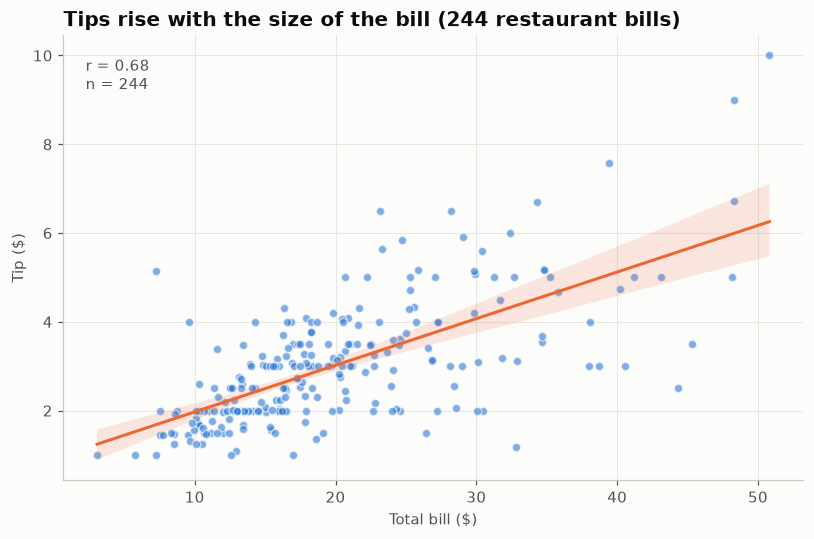

In [6]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.regplot(data=df, x=x, y=y, ax=ax, ci=95, seed=0,
            scatter_kws=dict(s=30, alpha=0.6, color=PALETTE[0], edgecolor="#fcfcfb"),
            line_kws=dict(color=PALETTE[1], linewidth=2))
ax.text(0.03, 0.95, f"r = {fit.rvalue:.2f}\nn = {len(df)}", transform=ax.transAxes,
        va="top", fontsize=10, color="#52514e")
ax.set_xlabel(labels["x"])
ax.set_ylabel(labels["y"])
ax.set_title(labels["title"])
fig.tight_layout()
plt.show()

---
Standalone script: [`scatter_regression.py`](scatter_regression.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)